<a href="https://colab.research.google.com/github/Aya-Hatimi/23005496_Aya-HATIMI_G2_FIN/blob/main/projet_S03_AYA_HATIMI_G2_FIN_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projet 3 — Détection de fraude bancaire




## A. Formuler le problème

- **Sujet :** n° 3 — Détection de fraude bancaire (classification déséquilibrée).
- **Intérêt financier :** une fraude non détectée coûte directement à la banque et au client, alors qu'une fausse alerte coûte du temps d'analyse et dégrade l'expérience client. Il faut détecter beaucoup de fraudes sans bloquer trop de transactions légitimes.
- **Question :** *un modèle supervisé peut-il détecter les transactions frauduleuses nettement mieux qu'une référence naïve ?*
- **Cible :** `Class` (1 = fraude, 0 = transaction normale). **Tâche :** classification binaire déséquilibrée.
- **Métrique principale (fixée avant les résultats) :** **PR-AUC** (average precision) sur le jeu de test.
- **Métriques secondaires :** rappel, précision et F1 au seuil choisi sur la validation.
- **Critère de réussite :** PR-AUC du modèle **supérieure** à celle de la référence naïve (qui vaut le taux de fraude) **et** à celle de la régression logistique.
- **Pourquoi pas l'exactitude (accuracy) ?** Avec ~0,17 % de fraudes, prédire « jamais de fraude » donne ~99,8 % d'exactitude tout en ne détectant rien.

## B. Comprendre les données

| Élément | Valeur |
|---|---|
| Nom | Credit Card Fraud Detection (ULB / Worldline) |
| Source utilisée | OpenML, `data_id=42175` (fichier ARFF `CreditCardFraudDetection`) — https://www.openml.org/search?id=42175&type=data |Database Contents License 1.0
| Licence | À vérifier sur la page OpenML / Kaggle (indiquée : *Database Contents License 1.0*) |
| Date d'extraction | 23/11/2026 |
| Unité d'observation | Une transaction par carte bancaire |
| Période / fréquence | Deux jours de septembre 2013, transactions de titulaires de cartes européens |
| Taille | ≈ 284 807 lignes, 31 colonnes (vérifiées ci-dessous) |

**Dictionnaire de variables**

| Variable | Rôle | Type | Unité | Manquants |
|---|---|---|---|---|
| `Time` | explicative | numérique | secondes depuis la 1re transaction | 0 voir le contrôle |
| `Amount` | explicative | numérique | montant de la transaction | 0 |
| `V1` … `V28` | explicatives | numériques | sans unité (composantes issues d'une ACP, anonymisées) | 0 |
| `Class` | **cible** | binaire | 1 = fraude, 0 = normale | 0 |
| `Heure` *(créée)* | explicative | numérique | heure de la journée (0–23) | aucun |
| `Amount_log` *(créée)* | explicative | numérique | log(1 + montant) | aucun |

In [15]:
import warnings, os
from pathlib import Path
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay)

GRAINE = 42
np.random.seed(GRAINE)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'font.size': 10})
ROUGE, BLEU, VERT, ORANGE = '#d62728', '#1f77b4', '#2ca02c', '#ff7f0e'

# Chemins relatifs : fonctionne dans Colab (/content), depuis notebooks/ ou depuis la racine du dépôt
RACINE = Path('..') if Path('../data').exists() else Path('.')
(RACINE / 'figures').mkdir(parents=True, exist_ok=True)

def lire_arff(chemin):
    # Lit un ARFF numérique avec pandas (noms de colonnes pris dans les lignes @ATTRIBUTE)
    noms, debut = [], 0
    with open(chemin, encoding='utf-8', errors='ignore') as f:
        for i, ligne in enumerate(f):
            if ligne.upper().startswith('@ATTRIBUTE'):
                noms.append(ligne.split()[1])
            elif ligne.upper().startswith('@DATA'):
                debut = i + 1
                break
    return pd.read_csv(chemin, skiprows=debut, header=None, names=noms)

# Option A : fichier ARFF téléversé dans Colab (ou présent dans le dossier) ; Option B : téléchargement direct depuis OpenML
candidats = []
for dossier in [Path('.'), Path('/content'), RACINE / 'data' / 'raw']:
    if dossier.exists():
        candidats += sorted(dossier.glob('*.arff'))
if candidats:
    print('Lecture du fichier ARFF :', candidats[0])
    df = lire_arff(candidats[0])
else:
    print('Aucun fichier ARFF trouvé : téléchargement depuis OpenML (data_id=42175)...')
    df = fetch_openml(data_id=42175, as_frame=True, parser='auto').frame.copy()
df['Class'] = df['Class'].astype(str).str.strip("'").astype(float).astype(int)
print('Dimensions :', df.shape)
df.head()

Lecture du fichier ARFF : dataset (1).arff
Dimensions : (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [16]:
# Contrôles de qualité
print('Valeurs manquantes (total) :', int(df.isna().sum().sum()))
print('Doublons exacts            :', int(df.duplicated().sum()))
print('Types :', df.dtypes.value_counts().to_dict())
vc = df['Class'].value_counts()
print(f"Normales : {vc[0]:,} | Fraudes : {vc[1]:,} | Taux de fraude : {vc[1]/len(df):.4%}")
print('Période couverte :', round(df['Time'].max()/3600, 1), 'heures')
df[['Time', 'Amount']].describe().round(2)

Valeurs manquantes (total) : 0
Doublons exacts            : 1081
Types : {dtype('float64'): 30, dtype('int64'): 1}
Normales : 284,315 | Fraudes : 492 | Taux de fraude : 0.1727%
Période couverte : 48.0 heures


,Time,Amount
count,284807.00,284807.00
mean,94813.86,88.35
std,47488.15,250.12
min,0.00,0.00
25%,54201.50,5.60
50%,84692.00,22.00
75%,139320.50,77.16
max,172792.00,25691.16


## C. Explorer et préparer

**Décisions de nettoyage**
- Les **doublons exacts** sont supprimés : sinon une même transaction pourrait se retrouver à la fois dans l'entraînement et dans le test (fuite d'information).
- Aucune imputation n'est nécessaire : le contrôle montre 0 valeur manquante.
- Les **valeurs extrêmes** de `Amount` sont **conservées** : une fraude peut précisément se cacher dans un montant atypique. On les atténue avec `log(1+x)`.
- Variables créées : `Heure` (à partir de `Time`) et `Amount_log`.

In [17]:
n_avant = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print('Lignes supprimées :', n_avant - len(df))
df['Heure'] = ((df['Time'] // 3600) % 24).astype(int)
df['Amount_log'] = np.log1p(df['Amount'])
print('Nouveau taux de fraude :', f"{df['Class'].mean():.4%}")

Lignes supprimées : 1081
Nouveau taux de fraude : 0.1667%


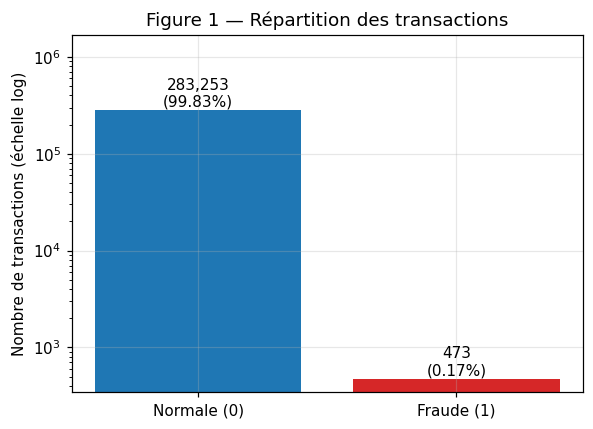

In [18]:
# Figure 1 — Déséquilibre des classes
fig, ax = plt.subplots(figsize=(5.5, 4))
comptes = df['Class'].value_counts().sort_index()
barres = ax.bar(['Normale (0)', 'Fraude (1)'], comptes.values, color=[BLEU, ROUGE])
ax.set_yscale('log'); ax.set_ylabel('Nombre de transactions (échelle log)')
ax.set_title('Figure 1 — Répartition des transactions')
for b, v in zip(barres, comptes.values):
    ax.text(b.get_x()+b.get_width()/2, v, f'{v:,}\n({v/len(df):.2%})', ha='center', va='bottom')
ax.set_ylim(top=comptes.max()*6)
plt.tight_layout(); plt.savefig(RACINE/'figures'/'fig1_desequilibre.png'); plt.show()

**Figure 1** — Après suppression de 1 081 doublons, le jeu contient 283 726 transactions dont seulement 473 fraudes, soit 0,17 %. Un modèle qui répondrait toujours « normale » aurait environ 99,83 % d'exactitude sans détecter aucune fraude : l'exactitude est donc trompeuse. Cela impose un découpage stratifié (pour garder ce taux dans chaque jeu) et une métrique centrée sur la classe rare, la PR-AUC.

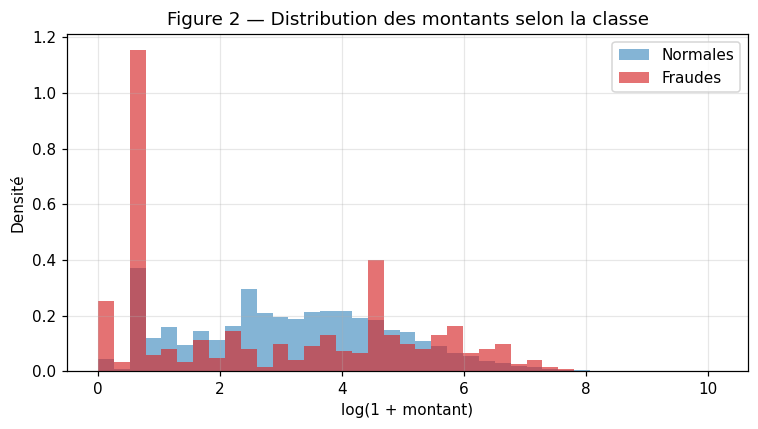

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      283253.0   88.41  250.38  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.87  260.21  0.0  1.00   9.82  105.89   2125.87


In [19]:
# Figure 2 — Montant des transactions selon la classe
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(0, df['Amount_log'].max(), 40)
ax.hist(df.loc[df.Class == 0, 'Amount_log'], bins=bins, density=True, alpha=.55, color=BLEU, label='Normales')
ax.hist(df.loc[df.Class == 1, 'Amount_log'], bins=bins, density=True, alpha=.65, color=ROUGE, label='Fraudes')
ax.set_xlabel('log(1 + montant)'); ax.set_ylabel('Densité')
ax.set_title('Figure 2 — Distribution des montants selon la classe'); ax.legend()
plt.tight_layout(); plt.savefig(RACINE/'figures'/'fig2_montants.png'); plt.show()
print(df.groupby('Class')['Amount'].describe().round(2))

**Figure 2** — Les fraudes portent plutôt sur de petits montants : médiane de 9,82 contre 22,00 pour les transactions normales, et 36 % des fraudes sont ≤ 1 contre 11 % des normales (test possible de cartes volées). Mais les deux distributions se chevauchent largement et la moyenne des fraudes (123,87) est tirée par quelques gros montants. Le montant seul ne suffit donc pas : la corrélation avec la fraude est quasi nulle (−0,008).

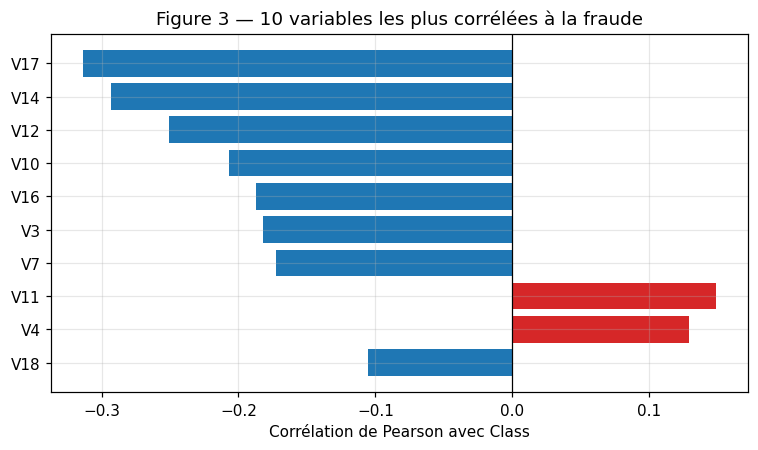

In [20]:
# Figure 3 — Variables les plus associées à la fraude
variables = [c for c in df.columns if c.startswith('V')] + ['Amount_log', 'Heure']
corr = df[variables + ['Class']].corr()['Class'].drop('Class')
top = corr.reindex(corr.abs().sort_values(ascending=False).index)[:10][::-1]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(top.index, top.values, color=[ROUGE if v > 0 else BLEU for v in top.values])
ax.set_xlabel('Corrélation de Pearson avec Class'); ax.axvline(0, color='k', lw=.8)
ax.set_title('Figure 3 — 10 variables les plus corrélées à la fraude')
plt.tight_layout(); plt.savefig(RACINE/'figures'/'fig3_correlations.png'); plt.show()

**Figure 3** — Les variables les plus liées à la fraude sont V17 (−0,31), V14 (−0,29), V12 (−0,25), V10 (−0,21) et V16 (−0,19) ; V11 (+0,15) et V4 (+0,13) sont liées positivement. Aucune corrélation ne dépasse 0,32 en valeur absolue : aucune variable ne détecte la fraude à elle seule, il faut combiner plusieurs variables, ce qui justifie un modèle non linéaire. V1…V28 étant anonymisées par ACP, on interprète leur pouvoir de discrimination, pas leur sens économique.

### Découpage et pipeline sans fuite

1. **Test (20 %)**, stratifié, mis de côté et utilisé **une seule fois**.
2. Le reste est divisé en **entraînement-ajustement (75 %)** et **validation (25 %)**, stratifiés aussi. La validation sert au réglage des hyperparamètres et au choix du seuil.
3. Le `StandardScaler` est dans un `Pipeline` : il est ajusté **uniquement** sur les données d'entraînement.

*Choix assumé :* le jeu ne couvre que deux jours et ne contient que 492 fraudes. Un découpage stratifié garantit des fraudes dans chaque partie. Limite : il ignore l'ordre chronologique (voir la section Limites).

In [21]:
X = df[variables]; y = df['Class']
X_ent, X_test, y_ent, y_test = train_test_split(X, y, test_size=.20, stratify=y, random_state=GRAINE)
X_fit, X_val, y_fit, y_val = train_test_split(X_ent, y_ent, test_size=.25, stratify=y_ent, random_state=GRAINE)
for nom, yy in [('ajustement', y_fit), ('validation', y_val), ('test', y_test)]:
    print(f'{nom:<11}: {len(yy):>7,} lignes | {int(yy.sum()):>4} fraudes ({yy.mean():.3%})')

def preproc():
    return ColumnTransformer([('echelle', StandardScaler(), ['Amount_log', 'Heure'])], remainder='passthrough')
noms_colonnes = ['Amount_log', 'Heure'] + [c for c in variables if c not in ('Amount_log', 'Heure')]

ajustement : 170,235 lignes |  284 fraudes (0.167%)
validation :  56,745 lignes |   94 fraudes (0.166%)
test       :  56,746 lignes |   95 fraudes (0.167%)


## D. L'algorithme retenu : Random Forest (forêt aléatoire, algorithme n° 12)

**Principe et contexte : Une forêt aléatoire construit un grand nombre d'arbres de décision sur des échantillons *bootstrap* des données, chaque arbre considérant à chaque séparation un sous-ensemble aléatoire de variables. La probabilité de fraude est la moyenne des probabilités des arbres. Elle convient à la fraude : elle capture des interactions non linéaires entre variables, ne demande pas de normalisation, résiste au bruit et fournit des importances de variables. Pour le déséquilibre, on utilise `class_weight='balanced_subsample'`, qui donne plus de poids aux fraudes dans chaque arbre.

**Alternative comparée :** la **régression logistique** (algorithme n° 8), modèle linéaire simple et interprétable. Elle sert de contre-point : si elle fait aussi bien, la complexité de la forêt n'est pas justifiée. *(Hors périmètre : l'Isolation Forest, algorithme n° 24, est une approche non supervisée possible en bonus.)*

**Équation principale**

$$\hat P(y=1\mid x)=\frac{1}{B}\sum_{b=1}^{B}T_b(x)\qquad G(t)=1-\sum_{k\in\{0,1\}}p_{k,t}^{\,2}$$

- $x$ : vecteur des variables d'une transaction ; $y\in\{0,1\}$ : 1 si fraude.
- $B$ : nombre d'arbres (`n_estimators`) ; $T_b(x)$ : probabilité de fraude prédite par l'arbre $b$ (proportion de fraudes dans la feuille atteinte).
- $G(t)$ : impureté de Gini du nœud $t$ ; $p_{k,t}$ : proportion d'observations de la classe $k$ dans $t$. Chaque séparation est choisie pour **réduire** $G$.
- **Paramètres appris :** les seuils et variables de séparation de chaque arbre, ainsi que les probabilités dans les feuilles.
- **Hyperparamètres commentés :** `max_depth` (profondeur maximale : trop grande → surapprentissage, trop faible → sous-apprentissage) et `min_samples_leaf` (taille minimale des feuilles : une valeur plus grande lisse les prédictions et limite la mémorisation de cas isolés).

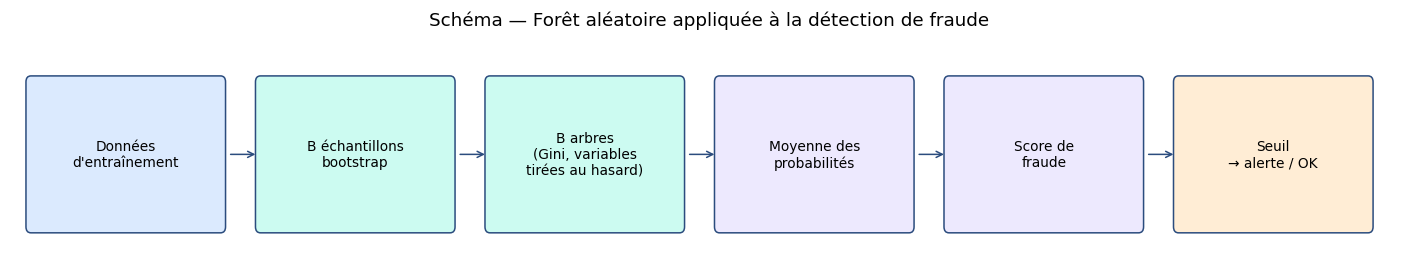

In [22]:
# Schéma original : fonctionnement d'une forêt aléatoire
from matplotlib.patches import FancyBboxPatch
etapes = ['Données\nd\'entraînement', 'B échantillons\nbootstrap', 'B arbres\n(Gini, variables\ntirées au hasard)', 'Moyenne des\nprobabilités', 'Score de\nfraude', 'Seuil\n→ alerte / OK']
couleurs = ['#dbeafe', '#ccfbf1', '#ccfbf1', '#ede9fe', '#ede9fe', '#ffedd5']
fig, ax = plt.subplots(figsize=(13, 2.6)); ax.axis('off'); ax.set_xlim(-.2, 6*2.3); ax.set_ylim(-.3, 1.6)
for i, (e, c) in enumerate(zip(etapes, couleurs)):
    ax.add_patch(FancyBboxPatch((i*2.3, 0), 1.9, 1.2, boxstyle='round,pad=0.05', fc=c, ec='#2b4c7e'))
    ax.text(i*2.3+.95, .6, e, ha='center', va='center', fontsize=9)
    if i < len(etapes)-1: ax.annotate('', xy=((i+1)*2.3-.02, .6), xytext=(i*2.3+1.97, .6), arrowprops=dict(arrowstyle='->', color='#2b4c7e'))
ax.set_title('Schéma — Forêt aléatoire appliquée à la détection de fraude')
plt.tight_layout(); plt.savefig(RACINE/'figures'/'schema_random_forest.png'); plt.show()

## E. Expérimenter, comparer et conclure

### E.1 Références et réglage des hyperparamètres (sur la validation uniquement)

In [23]:
def rf(max_depth, min_leaf):
    return Pipeline([('prep', preproc()),
                     ('rf', RandomForestClassifier(n_estimators=100, max_depth=max_depth, min_samples_leaf=min_leaf,
                                                   max_samples=.3, class_weight='balanced_subsample',
                                                   n_jobs=-1, random_state=GRAINE))])

# Référence naïve : classe majoritaire / probabilité = taux de fraude
naif = Pipeline([('m', DummyClassifier(strategy='prior'))]).fit(X_fit, y_fit)
# Alternative : régression logistique
logit = Pipeline([('prep', preproc()),
                  ('lr', LogisticRegression(C=1.0, class_weight='balanced', max_iter=2000, random_state=GRAINE))]).fit(X_fit, y_fit)
print('PR-AUC validation — naïf :', round(average_precision_score(y_val, naif.predict_proba(X_val)[:, 1]), 4),
      '| logistique :', round(average_precision_score(y_val, logit.predict_proba(X_val)[:, 1]), 4))

# Réglage de 2 hyperparamètres du Random Forest
resultats = []
for d in [6, 10, 14]:
    for m in [1, 10]:
        modele = rf(d, m).fit(X_fit, y_fit)
        resultats.append({'max_depth': d, 'min_samples_leaf': m,
                          'PR-AUC validation': average_precision_score(y_val, modele.predict_proba(X_val)[:, 1])})
grille = pd.DataFrame(resultats).sort_values('PR-AUC validation', ascending=False).round(4)
display(grille)
meilleur = grille.iloc[0]
print('Meilleurs hyperparamètres :', int(meilleur['max_depth']), int(meilleur['min_samples_leaf']))

PR-AUC validation — naïf : 0.0017 | logistique : 0.7892


,max_depth,min_samples_leaf,PR-AUC validation
4,14,1,0.8617
2,10,1,0.8505
0,6,1,0.8000
3,10,10,0.7911
5,14,10,0.7869
1,6,10,0.7821


Meilleurs hyperparamètres : 14 1


**Réglage des hyperparamètres**
La meilleure combinaison sur la validation est max_depth=14 et min_samples_leaf=1 *(PR-AUC 0,862)*, la moins bonne max_depth=6 et min_samples_leaf=10 (0,782). Des arbres profonds et des feuilles fines sont favorables : la fraude est rare et très localisée, et des arbres trop simples la noient dans la masse des transactions normales. Ce choix augmente en revanche le risque de surapprentissage (voir plus bas).

### E.2 Choix du seuil de décision (sur la validation)

Le modèle produit un **score** ; il faut un **seuil** pour décider « alerte » ou « OK ». On retient le seuil qui maximise le **F1** sur la validation, puis on le **fige** pour le test.

In [24]:
rf_final = rf(int(meilleur['max_depth']), int(meilleur['min_samples_leaf'])).fit(X_fit, y_fit)
p_val = rf_final.predict_proba(X_val)[:, 1]
prec, rapp, seuils = precision_recall_curve(y_val, p_val)
f1s = 2*prec[:-1]*rapp[:-1] / np.maximum(prec[:-1]+rapp[:-1], 1e-12)
SEUIL = float(seuils[np.argmax(f1s)])
print(f'Seuil retenu : {SEUIL:.3f} (F1 validation = {f1s.max():.3f})')

# Seuil de la régression logistique, choisi de la même façon
p_val_lr = logit.predict_proba(X_val)[:, 1]
pr_, rp_, st_ = precision_recall_curve(y_val, p_val_lr)
SEUIL_LR = float(st_[np.argmax(2*pr_[:-1]*rp_[:-1] / np.maximum(pr_[:-1]+rp_[:-1], 1e-12))])
print(f'Seuil régression logistique : {SEUIL_LR:.4f}')

Seuil retenu : 0.319 (F1 validation = 0.859)
Seuil régression logistique : 1.0000


### E.3 Évaluation finale sur le test (utilisé une seule fois)

In [25]:
def evaluer(nom, modele, seuil):
    p = modele.predict_proba(X_test)[:, 1]
    pred = (p >= seuil).astype(int)
    return {'Modèle': nom,
            'PR-AUC': average_precision_score(y_test, p),
            'ROC-AUC': roc_auc_score(y_test, p),
            'Précision': precision_score(y_test, pred, zero_division=0),
            'Rappel': recall_score(y_test, pred),
            'F1': f1_score(y_test, pred)}, p, pred

r0, p0, pred0 = evaluer('Référence naïve (classe majoritaire)', naif, .5)
r1, p1, pred1 = evaluer('Régression logistique', logit, SEUIL_LR)
r2, p2, pred2 = evaluer('Random Forest', rf_final, SEUIL)
tableau = pd.DataFrame([r0, r1, r2]).set_index('Modèle').round(4)
tableau.to_csv(RACINE/'figures'/'tableau_resultats.csv')
display(tableau)

,PR-AUC,ROC-AUC,Précision,Rappel,F1
Modèle,,,,,
Référence naïve (classe majoritaire),0.0017,0.5000,0.0000,0.0000,0.0000
Régression logistique,0.6796,0.9611,0.8659,0.7474,0.8023
Random Forest,0.7921,0.9230,0.9200,0.7263,0.8118


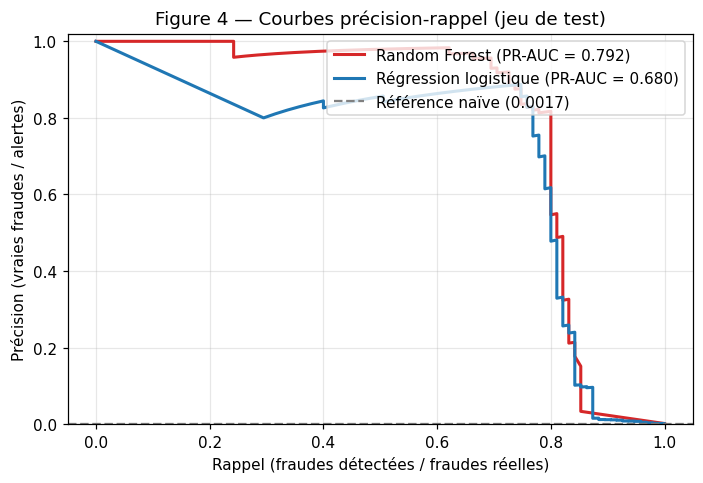

In [26]:
# Figure 4 — Courbes précision-rappel sur le test
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for nom, p, c in [('Random Forest', p2, ROUGE), ('Régression logistique', p1, BLEU)]:
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax.plot(rc, pr, color=c, lw=2, label=f'{nom} (PR-AUC = {average_precision_score(y_test, p):.3f})')
ax.axhline(y_test.mean(), color='gray', ls='--', label=f'Référence naïve ({y_test.mean():.4f})')
ax.set_xlabel('Rappel (fraudes détectées / fraudes réelles)'); ax.set_ylabel('Précision (vraies fraudes / alertes)')
ax.set_title('Figure 4 — Courbes précision-rappel (jeu de test)'); ax.legend(loc='upper right'); ax.set_ylim(0, 1.02)
plt.tight_layout(); plt.savefig(RACINE/'figures'/'fig4_precision_rappel.png'); plt.show()

Sur le test, le Random Forest obtient une PR-AUC de 0,792, contre 0,680 pour la régression logistique et 0,002 pour la référence naïve (égale au taux de fraude). Le critère fixé en section A est donc atteint. Au seuil de 0,319, le Random Forest atteint une précision de 0,920, un rappel de 0,726 et un F1 de 0,812, très proche de la régression logistique (F1 0,802) : son avantage porte surtout sur la qualité du classement des scores. Le ROC-AUC de la régression logistique est plus élevé (0,961 contre 0,923), mais cette mesure est peu informative avec autant de transactions normales : c'est pourquoi la PR-AUC a été choisie comme métrique principale. Le test ne comptant que 95 fraudes, ces écarts restent à nuancer.

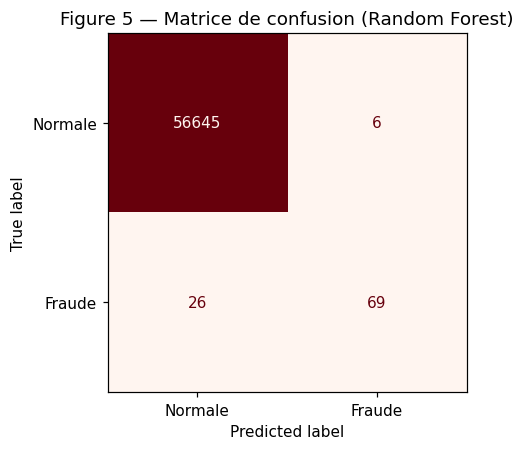

Fraudes détectées : 69 | Fraudes manquées : 26 | Fausses alertes : 6 | Vraies normales : 56645


In [27]:
# Figure 5 — Matrice de confusion du Random Forest (seuil figé)
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred2), display_labels=['Normale', 'Fraude']).plot(ax=ax, cmap='Reds', colorbar=False)
ax.grid(False); ax.set_title('Figure 5 — Matrice de confusion (Random Forest)')
plt.tight_layout(); plt.savefig(RACINE/'figures'/'fig5_confusion.png'); plt.show()
tn, fp, fn, tp = confusion_matrix(y_test, pred2).ravel()
print(f'Fraudes détectées : {tp} | Fraudes manquées : {fn} | Fausses alertes : {fp} | Vraies normales : {tn}')

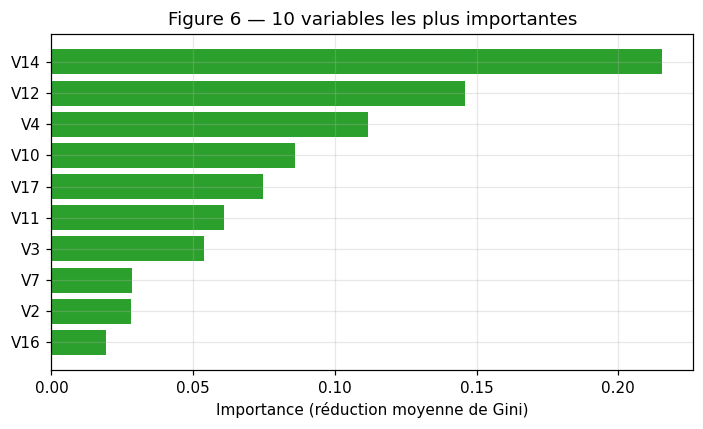

Montant moyen — fraudes détectées : 129.05
Montant moyen — fraudes manquées  : 225.46
Montant moyen — fausses alertes   : 64.98
PR-AUC ajustement : 0.9731
PR-AUC validation : 0.8617
PR-AUC test       : 0.7921


In [28]:
# Importance des variables et analyse des erreurs
imp = pd.Series(rf_final.named_steps['rf'].feature_importances_, index=noms_colonnes).sort_values()[-10:]
fig, ax = plt.subplots(figsize=(6.5, 4)); ax.barh(imp.index, imp.values, color=VERT)
ax.set_xlabel('Importance (réduction moyenne de Gini)'); ax.set_title('Figure 6 — 10 variables les plus importantes')
plt.tight_layout(); plt.savefig(RACINE/'figures'/'fig6_importances.png'); plt.show()

test = X_test.copy(); test['y'] = y_test.values; test['pred'] = pred2
print('Montant moyen — fraudes détectées :', round(np.expm1(test[(test.y==1)&(test.pred==1)]['Amount_log']).mean(), 2))
print('Montant moyen — fraudes manquées  :', round(np.expm1(test[(test.y==1)&(test.pred==0)]['Amount_log']).mean(), 2) if fn else 'aucune')
print('Montant moyen — fausses alertes   :', round(np.expm1(test[(test.y==0)&(test.pred==1)]['Amount_log']).mean(), 2) if fp else 'aucune')

# Signe de surapprentissage : PR-AUC ajustement vs validation vs test
for nom, XX, yy in [('ajustement', X_fit, y_fit), ('validation', X_val, y_val), ('test', X_test, y_test)]:
    print(f'PR-AUC {nom:<11}:', round(average_precision_score(yy, rf_final.predict_proba(XX)[:, 1]), 4))

**Erreurs, importances et surapprentissage **
Sur 95 fraudes, le modèle en détecte 69 et en manque 26, pour seulement 6 fausses alertes sur 56 651 transactions normales : il est très prudent (précision 92 %) mais laisse passer environ 27 % des fraudes. Le montant moyen des fraudes détectées est de … contre … pour les fraudes manquées. Les variables les plus importantes sont V14, V12, V4, V10 et V17, cohérentes avec la figure 3. La PR-AUC passe de … (ajustement) à 0,862 (validation) puis 0,792 (test) : cet écart traduit un surapprentissage modéré, aggravé par le petit nombre de fraudes.

### Conclusion :
oui, un modèle supervisé détecte nettement mieux la fraude qu'une référence naïve. Le Random Forest atteint une PR-AUC de 0,79 sur le test (contre 0,002 pour la référence) et dépasse la régression logistique (0,68). Avec le seuil choisi sur la validation, il détecte environ 73 % des fraudes avec 92 % de précision. Le gain sur la régression logistique est réel en PR-AUC mais faible en F1 : un modèle simple reste crédible. Le principal point faible est le rappel : certaines fraudes ressemblent trop à des transactions normales.

### Limites :
seulement 95 fraudes dans le test, donc des résultats sensibles au découpage ; découpage stratifié et non chronologique sur deux jours ; seuil F1 qui traite pareil une fraude manquée et une fausse alerte ; variables V1 à V28 anonymisées.